<a href="https://colab.research.google.com/github/Pakvlaxd/algorytmika_zajecia/blob/main/lab/Michal_Pakula_lab1_sprawozdanie.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sprawozdanie laboratoryjne

Przedmiot: Uczenie głębokie do rozpoznawania obiektów
Zajęcia nr 1 / temat: Obraz jako dane; od neuronu do klasyfikatora obrazów
Autor / grupa: Michał Pakuła / GL.03
Data: 13.10.2026

## 1. Cel ćwiczenia
Celem jest wytrenowanie perceptronu wielowarstwowego (MLP) rozpoznającego 10 kategorii odzieży ze zbioru FashionMNIST, zbadanie wpływu architektury (liczba i rozmiar warstw ukrytych) na accuracy, analiza krzywych uczenia (przeuczenie) oraz analiza błędnych predykcji. Zakres dodatkowy: macierz pomyłek, wpływ współczynnika uczenia i liczby epok.

Uzasadnienie wyboru zbioru (FashionMNIST zamiast CIFAR-10):
- obrazy 28×28 w skali szarości (1 kanał), więc `in_dim = 784`, a normalizacja jest jednokanałowa,
- szybki trening, co pozwala przetestować wiele wariantów,
- klasy mają interpretowalne pomyłki (np. koszula vs koszulka)

## 2. Metoda i implementacja
Narzędzia: Python, PyTorch, torchvision, matplotlib, pandas, scikit-learn (macierz pomyłek, raport klasyfikacji). Uruchamiane w Google Colab (GPU).

Konfiguracja:

| Element | Wartość |
|---|---|
| Zbiór | FashionMNIST: 60 000 trening / 10 000 test |
| Preprocessing | `ToTensor` + `Normalize(0.2860, 0.3530)` |
| Model | `Flatten` → [`Linear` → `ReLU`] × k → `Linear(10)` |
| Funkcja straty | Cross-Entropy |
| Optymalizator | Adam, lr = 1e-3 (bazowo) |
| Batch size | 128 (trening), 256 (test) |
| Epoki | 10 (bazowo), 40 (eksperyment z liczbą epok) |
| Seed | 0 (ten sam dla wszystkich wariantów) |
| Augmentacje | brak |

Użyto AI do przygotowania szkieletu notebooka, zredagowania wniosków oraz sprawdzenia poprawności i stylu kodu

In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt

SEED = 0
torch.manual_seed(SEED)
np.random.seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| urządzenie:", device)

PyTorch: 2.11.0+cpu | urządzenie: cpu


In [2]:
mean, std = 0.2860, 0.3530  # statystyki FashionMNIST (1 kanał)
tf = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Normalize((mean,), (std,)),
    ]
)

train_ds = torchvision.datasets.FashionMNIST(
    "./data", train=True, download=True, transform=tf
)
test_ds = torchvision.datasets.FashionMNIST(
    "./data", train=False, download=True, transform=tf
)
classes = train_ds.classes
print("Klasy:", classes)
print("Trening:", len(train_ds), "| Test:", len(test_ds))

train_dl = DataLoader(train_ds, batch_size=128, shuffle=True)
test_dl = DataLoader(test_ds, batch_size=256, shuffle=False)

img_t, label = train_ds[0]
print(
    "Kształt tensora obrazu:",
    tuple(img_t.shape),
    "| etykieta:",
    classes[label],
)

100%|██████████| 26.4M/26.4M [00:01<00:00, 21.4MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 345kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 6.25MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 11.9MB/s]

Klasy: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
Trening: 60000 | Test: 10000
Kształt tensora obrazu: (1, 28, 28) | etykieta: Ankle boot


In [3]:
def make_mlp(hidden=(256, 128), in_dim=28 * 28, n_classes=10):
    layers = [nn.Flatten()]
    prev = in_dim
    for h in hidden:
        layers += [nn.Linear(prev, h), nn.ReLU()]
        prev = h
    layers.append(nn.Linear(prev, n_classes))
    return nn.Sequential(*layers)


def count_params(model):
    return sum(p.numel() for p in model.parameters())


@torch.no_grad()
def evaluate(model, dl):
    model.eval()
    crit = nn.CrossEntropyLoss(reduction="sum")
    loss_sum, correct, total = 0.0, 0, 0
    for xb, yb in dl:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        loss_sum += crit(out, yb).item()
        correct += (out.argmax(1) == yb).sum().item()
        total += yb.numel()
    return loss_sum / total, correct / total


def train_model(hidden, epochs=10, lr=1e-3, seed=SEED, verbose=False):
    torch.manual_seed(seed)
    model = make_mlp(hidden).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    crit = nn.CrossEntropyLoss()
    hist = {"train_loss": [], "test_loss": [], "test_acc": []}
    for ep in range(1, epochs + 1):
        model.train()
        run = 0.0
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = crit(model(xb), yb)
            loss.backward()
            opt.step()
            run += loss.item() * yb.numel()
        tr = run / len(train_ds)
        te_loss, te_acc = evaluate(model, test_dl)
        hist["train_loss"].append(tr)
        hist["test_loss"].append(te_loss)
        hist["test_acc"].append(te_acc)
        if verbose:
            print(
                f"Epoka {ep:2d} | trening {tr:.3f} | test {te_loss:.3f} | "
                f"acc {te_acc * 100:.2f}%"
            )
    return model, hist


@torch.no_grad()
def predict_all(model, dl):
    model.eval()
    preds, labels = [], []
    for xb, yb in dl:
        preds.append(model(xb.to(device)).argmax(1).cpu())
        labels.append(yb)
    return torch.cat(preds).numpy(), torch.cat(labels).numpy()

## 3. Wyniki

### 3.1 Model bazowy
Bazowy = model z ćwiczenia: `(256, 128)`

In [4]:
EPOCHS = 10
base_model, base_hist = train_model(
    (256, 128), epochs=EPOCHS, lr=1e-3, verbose=True
)
base_acc = base_hist["test_acc"][-1]
print(
    f"\nModel bazowy (256,128): accuracy na zbiorze testowym = "
    f"{base_acc * 100:.2f}% | parametry: {count_params(base_model):,}"
)

Epoka  1 | trening 0.489 | test 0.414 | acc 84.79%
Epoka  2 | trening 0.351 | test 0.355 | acc 87.17%
Epoka  3 | trening 0.312 | test 0.356 | acc 87.25%
Epoka  4 | trening 0.286 | test 0.345 | acc 87.54%
Epoka  5 | trening 0.267 | test 0.343 | acc 87.52%
Epoka  6 | trening 0.253 | test 0.333 | acc 88.18%
Epoka  7 | trening 0.234 | test 0.320 | acc 88.60%
Epoka  8 | trening 0.221 | test 0.334 | acc 88.62%
Epoka  9 | trening 0.211 | test 0.334 | acc 88.28%
Epoka 10 | trening 0.200 | test 0.379 | acc 88.16%

Model bazowy (256,128): accuracy na zbiorze testowym = 88.16% | parametry: 235,146


### 3.2 Wpływ architektury
Kontrola liczby parametrów: `(128,)` → 101 770, `(256,128)` → 235 146, `(512,256,128)` → 567 434.

In [5]:
variants = [(64,), (128,), (256, 128), (512, 256, 128), (1024, 512, 256)]
results = {}
for hid in variants:
    m, h = train_model(hid, epochs=EPOCHS, lr=1e-3)
    results[hid] = {"model": m, "hist": h, "params": count_params(m)}
    print(
        f"{str(hid):18s} | parametry {results[hid]['params']:>9,} | "
        f"acc {h['test_acc'][-1] * 100:.2f}%"
    )

rows = []
for hid, r in results.items():
    h = r["hist"]
    rows.append(
        {
            "architektura": str(hid),
            "liczba parametrów": r["params"],
            "accuracy test [%]": round(h["test_acc"][-1] * 100, 2),
            "strata trening": round(h["train_loss"][-1], 3),
            "strata test": round(h["test_loss"][-1], 3),
            "luka test−trening": round(
                h["test_loss"][-1] - h["train_loss"][-1], 3
            ),
        }
    )
df = pd.DataFrame(rows)
display(df)
print(df.to_markdown(index=False))

(64,)              | parametry    50,890 | acc 87.36%
(128,)             | parametry   101,770 | acc 88.54%
(256, 128)         | parametry   235,146 | acc 88.16%
(512, 256, 128)    | parametry   567,434 | acc 88.19%
(1024, 512, 256)   | parametry 1,462,538 | acc 88.36%


,architektura,liczba parametrów,accuracy test [%],strata trening,strata test,luka test−trening
0,"(64,)",50890,87.36,0.258,0.360,0.103
1,"(128,)",101770,88.54,0.224,0.337,0.113
2,"(256, 128)",235146,88.16,0.200,0.379,0.179
3,"(512, 256, 128)",567434,88.19,0.199,0.349,0.150
4,"(1024, 512, 256)",1462538,88.36,0.189,0.400,0.211


| architektura     |   liczba parametrów |   accuracy test [%] |   strata trening |   strata test |   luka test−trening |
|:-----------------|--------------------:|--------------------:|-----------------:|--------------:|--------------------:|
| (64,)            |               50890 |               87.36 |            0.258 |         0.36  |               0.103 |
| (128,)           |              101770 |               88.54 |            0.224 |         0.337 |               0.113 |
| (256, 128)       |              235146 |               88.16 |            0.2   |         0.379 |               0.179 |
| (512, 256, 128)  |              567434 |               88.19 |            0.199 |         0.349 |               0.15  |
| (1024, 512, 256) |             1462538 |               88.36 |            0.189 |         0.4   |               0.211 |


Najlepszy wariant: (128,) | acc 88.54%


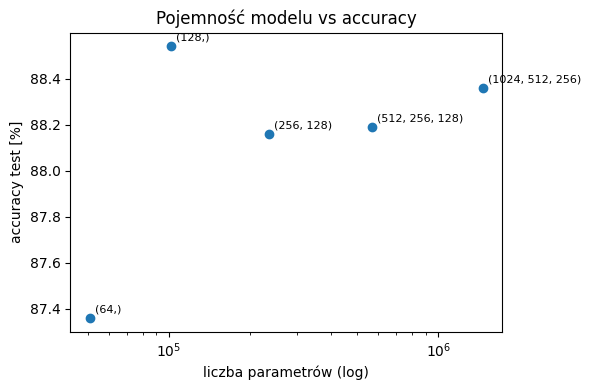

In [6]:
best_hid = max(results, key=lambda k: results[k]["hist"]["test_acc"][-1])
best = results[best_hid]
print(
    "Najlepszy wariant:",
    best_hid,
    f"| acc {best['hist']['test_acc'][-1]*100:.2f}%",
)

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(
    [r["params"] for r in results.values()],
    [r["hist"]["test_acc"][-1] * 100 for r in results.values()],
)
for hid, r in results.items():
    ax.annotate(
        str(hid),
        (r["params"], r["hist"]["test_acc"][-1] * 100),
        fontsize=8,
        xytext=(4, 4),
        textcoords="offset points",
    )
ax.set_xscale("log")
ax.set_xlabel("liczba parametrów (log)")
ax.set_ylabel("accuracy test [%]")
ax.set_title("Pojemność modelu vs accuracy")
plt.tight_layout()
plt.show()

In [7]:
base_acc_pct = base_acc * 100
best_acc_pct = best["hist"]["test_acc"][-1] * 100
print(f"Baseline (256,128): {base_acc_pct:.2f}%")
print(f"Najlepszy {best_hid}: {best_acc_pct:.2f}%")
print(f"Różnica względem baseline: {best_acc_pct - base_acc_pct:+.2f} p.p.")

Baseline (256,128): 88.16%
Najlepszy (128,): 88.54%
Różnica względem baseline: +0.38 p.p.


### 3.3 Krzywe uczenia najlepszego wariantu

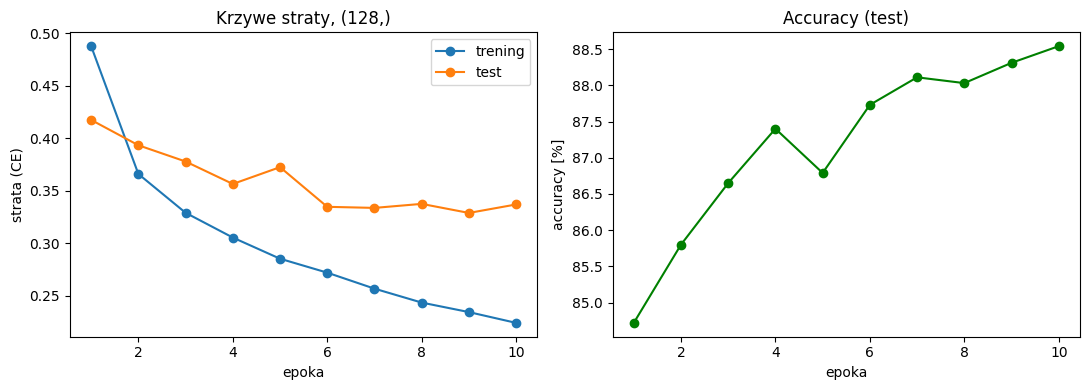

In [8]:
h = best["hist"]
epochs_axis = range(1, len(h["train_loss"]) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(epochs_axis, h["train_loss"], marker="o", label="trening")
ax1.plot(epochs_axis, h["test_loss"], marker="o", label="test")
ax1.set_xlabel("epoka")
ax1.set_ylabel("strata (CE)")
ax1.legend()
ax1.set_title(f"Krzywe straty, {best_hid}")
ax2.plot(
    epochs_axis, [a * 100 for a in h["test_acc"]], marker="o", color="green"
)
ax2.set_xlabel("epoka")
ax2.set_ylabel("accuracy [%]")
ax2.set_title("Accuracy (test)")
plt.tight_layout()
plt.show()

### 3.4 Przykładowe predykcje (trafne i błędne)

Błędnych predykcji: 1146 z 10000


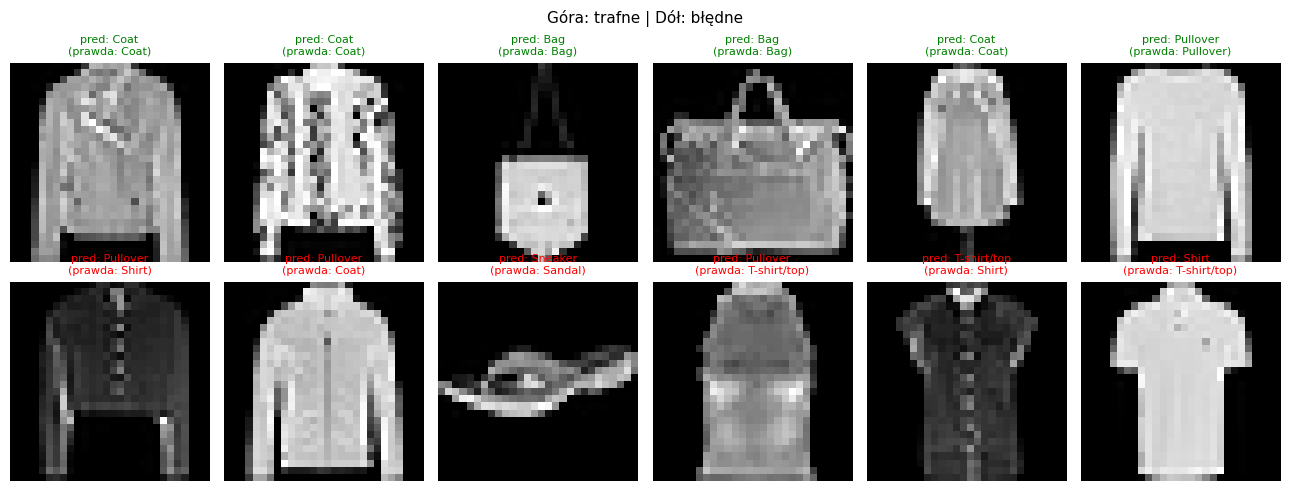

In [9]:
preds, labels = predict_all(best["model"], test_dl)
raw = test_ds.data.numpy()
ok_idx = np.where(preds == labels)[0]
bad_idx = np.where(preds != labels)[0]
print(f"Błędnych predykcji: {len(bad_idx)} z {len(labels)}")

rng = np.random.default_rng(SEED)
show_ok = rng.choice(ok_idx, 6, replace=False)
show_bad = rng.choice(bad_idx, 6, replace=False)

fig, axes = plt.subplots(2, 6, figsize=(13, 5))
for ax, i in zip(axes[0], show_ok):
    ax.imshow(raw[i], cmap="gray")
    ax.axis("off")
    ax.set_title(
        f"pred: {classes[preds[i]]}\n(prawda: {classes[labels[i]]})",
        fontsize=8,
        color="green",
    )
for ax, i in zip(axes[1], show_bad):
    ax.imshow(raw[i], cmap="gray")
    ax.axis("off")
    ax.set_title(
        f"pred: {classes[preds[i]]}\n(prawda: {classes[labels[i]]})",
        fontsize=8,
        color="red",
    )
fig.suptitle("Góra: trafne | Dół: błędne", fontsize=11)
plt.tight_layout()
plt.show()

### 3.5 Metryki per klasa i macierz pomyłek
Oprócz accuracy podajemy precision/recall/F1 per klasa oraz macierz pomyłek z najtrudniejszymi parami klas.

In [10]:
from sklearn.metrics import classification_report

print(classification_report(labels, preds, target_names=classes, digits=3))

              precision    recall  f1-score   support

 T-shirt/top      0.874     0.818     0.845      1000
     Trouser      0.989     0.970     0.979      1000
    Pullover      0.743     0.848     0.792      1000
       Dress      0.900     0.892     0.896      1000
        Coat      0.811     0.797     0.804      1000
      Sandal      0.971     0.954     0.963      1000
       Shirt      0.729     0.698     0.713      1000
     Sneaker      0.910     0.972     0.940      1000
         Bag      0.966     0.970     0.968      1000
  Ankle boot      0.977     0.935     0.956      1000

    accuracy                          0.885     10000
   macro avg      0.887     0.885     0.886     10000
weighted avg      0.887     0.885     0.886     10000



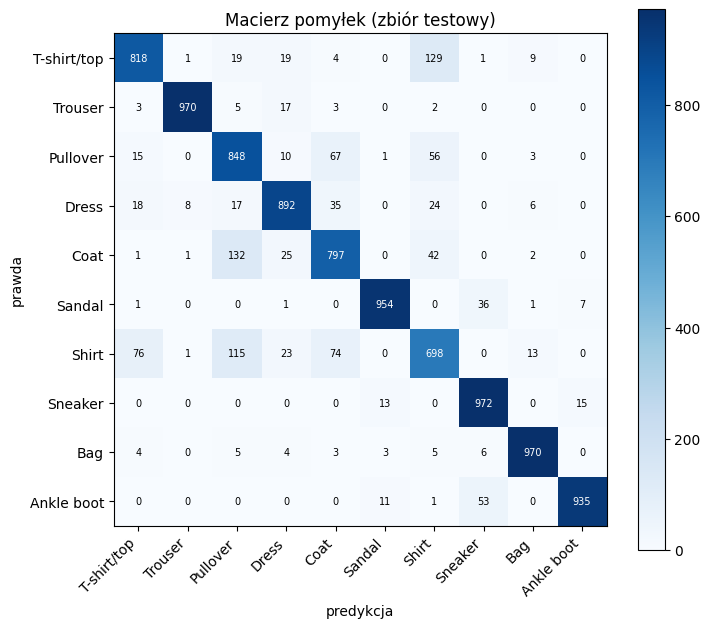

Accuracy per klasa:
  Shirt         69.8%
  Coat          79.7%
  T-shirt/top   81.8%
  Pullover      84.8%
  Dress         89.2%
  Ankle boot    93.5%
  Sandal        95.4%
  Trouser       97.0%
  Bag           97.0%
  Sneaker       97.2%

Najtrudniejsze pary klas (suma pomyłek w obie strony):
  T-shirt/top <-> Shirt: 205  (T-shirt/top→Shirt: 129, Shirt→T-shirt/top: 76)
  Pullover <-> Coat: 199  (Pullover→Coat: 67, Coat→Pullover: 132)
  Pullover <-> Shirt: 171  (Pullover→Shirt: 56, Shirt→Pullover: 115)


In [11]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(labels, preds)

fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10))
ax.set_xticklabels(classes, rotation=45, ha="right")
ax.set_yticks(range(10))
ax.set_yticklabels(classes)
for i in range(10):
    for j in range(10):
        ax.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center",
            fontsize=7,
            color="white" if cm[i, j] > cm.max() / 2 else "black",
        )
ax.set_xlabel("predykcja")
ax.set_ylabel("prawda")
ax.set_title("Macierz pomyłek (zbiór testowy)")
plt.colorbar(im)
plt.tight_layout()
plt.show()

# accuracy per klasa
per_class = cm.diagonal() / cm.sum(1)
print("Accuracy per klasa:")
for c, a in sorted(zip(classes, per_class), key=lambda t: t[1]):
    print(f"  {c:12s} {a*100:5.1f}%")

# najtrudniejsze pary
off = cm.copy()
np.fill_diagonal(off, 0)
pairs = [
    (off[i, j] + off[j, i], i, j) for i in range(10) for j in range(i + 1, 10)
]
print("\nNajtrudniejsze pary klas (suma pomyłek w obie strony):")
for tot, i, j in sorted(pairs, reverse=True)[:3]:
    print(
        f"  {classes[i]} <-> {classes[j]}: {tot}  "
        f"({classes[i]}→{classes[j]}: {off[i, j]}, "
        f"{classes[j]}→{classes[i]}: {off[j, i]})"
    )

### 3.6 Wpływ współczynnika uczenia i liczby epok

,lr,accuracy test [%],strata test
0,0.0001,86.35,0.382
1,0.0010,88.54,0.337
2,0.0100,86.10,0.420
3,0.0500,71.82,0.830


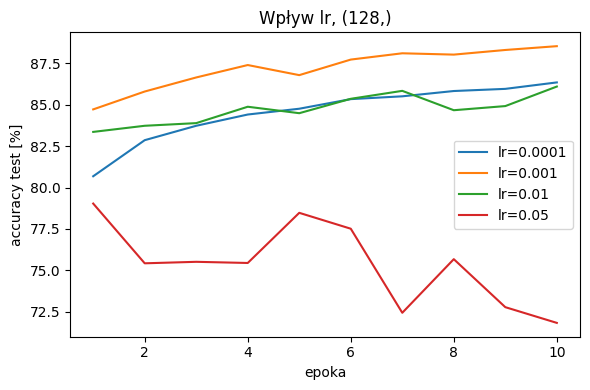

In [12]:
lrs = [1e-4, 1e-3, 1e-2, 5e-2]
lr_rows, lr_hists = [], {}
for lr in lrs:
    _, hh = train_model(best_hid, epochs=EPOCHS, lr=lr)
    lr_hists[lr] = hh
    lr_rows.append(
        {
            "lr": lr,
            "accuracy test [%]": round(hh["test_acc"][-1] * 100, 2),
            "strata test": round(hh["test_loss"][-1], 3),
        }
    )
display(pd.DataFrame(lr_rows))

fig, ax = plt.subplots(figsize=(6, 4))
for lr, hh in lr_hists.items():
    ax.plot(
        range(1, EPOCHS + 1),
        [a * 100 for a in hh["test_acc"]],
        label=f"lr={lr}",
    )
ax.set_xlabel("epoka")
ax.set_ylabel("accuracy test [%]")
ax.legend()
ax.set_title(f"Wpływ lr, {best_hid}")
plt.tight_layout()
plt.show()

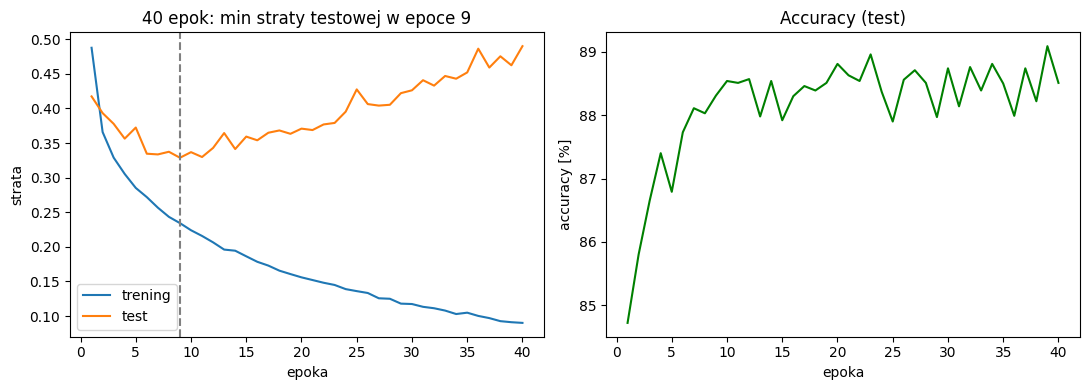

Najlepsza accuracy: 89.09% (epoka 39) | na końcu: 88.51%


In [13]:
LONG = 40
_, long_h = train_model(best_hid, epochs=LONG, lr=1e-3)
ep = range(1, LONG + 1)
best_ep = int(np.argmin(long_h["test_loss"])) + 1
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(ep, long_h["train_loss"], label="trening")
ax1.plot(ep, long_h["test_loss"], label="test")
ax1.axvline(best_ep, ls="--", color="gray")
ax1.legend()
ax1.set_xlabel("epoka")
ax1.set_ylabel("strata")
ax1.set_title(f"{LONG} epok: min straty testowej w epoce {best_ep}")
ax2.plot(ep, [a * 100 for a in long_h["test_acc"]], color="green")
ax2.set_xlabel("epoka")
ax2.set_ylabel("accuracy [%]")
ax2.set_title("Accuracy (test)")
plt.tight_layout()
plt.show()
print(
    f"Najlepsza accuracy: {max(long_h['test_acc']) * 100:.2f}% "
    f"(epoka {int(np.argmax(long_h['test_acc'])) + 1}) | "
    f"na końcu: {long_h['test_acc'][-1] * 100:.2f}%"
)

## 4. Analiza i interpretacja
## 4. Analiza i interpretacja

**Architektura.** Wszystkie warianty osiągnęły 87,4–88,5% accuracy. Najsłabszy był najmniejszy model (64,): 87,36% przy 50 890 parametrach, więc zbyt mała pojemność ogranicza wynik. Powyżej ok. 100 tys. parametrów zysk się nasyca: (128,) uzyskał 88,54%, a modele większe (235 tys. – 1,46 mln parametrów) 88,16–88,36%. Różnice między wariantami z ≥128 neuronami (≤0,4 p.p.) są małe, a przy jednym seedzie i wahaniach accuracy między epokami rzędu ±0,5 p.p. nie można ich uznać za istotne. Większe sieci mają natomiast wyraźnie większą lukę strata test − trening ((256,128): 0,179; (1024,512,256): 0,211; (128,): 0,113), czyli silniejsze przeuczenie. Najlepszym kompromisem jest (128,): najwyższa accuracy przy 2,3× mniejszej liczbie parametrów niż baseline.

**Krzywe uczenia i przeuczenie.** Dla (128,) strata treningowa maleje stale (0,49 → 0,22), a strata testowa przestaje maleć ok. 6. epoki (ok. 0,33–0,34). W eksperymencie na 40 epok minimum straty testowej wypada w epoce 9, po czym strata testowa rośnie do ok. 0,49, podczas gdy treningowa spada do ok. 0,09. To typowe przeuczenie: model zaczyna zapamiętywać zbiór treningowy. Accuracy w tym czasie nie spada (utrzymuje się ok. 88–89%, maks. 89,09% w epoce 39, na końcu 88,51%), bo model nadal trafia w większość przypadków, ale staje się coraz pewniejszy także przy błędnych odpowiedziach, a entropia krzyżowa karze za taką pewność. Wniosek: dla tego modelu wystarcza ok. 8–10 epok, dalej przydałby się early stopping.

**Przypadki błędne.** Model pomylił się w 1146 z 10 000 przypadków. Najlepiej rozpoznawane są klasy o wyrazistej, odrębnej sylwetce: Trouser (F1 = 0,979), Bag (0,968), Sandal (0,963) i Ankle boot (0,956). Najgorzej: Shirt (F1 = 0,713, recall 69,8%), Pullover (0,792), Coat (0,804) i T-shirt/top (0,845). Najtrudniejsze pary klas (suma pomyłek w obie strony): T-shirt/top ↔ Shirt (205), Pullover ↔ Coat (199) oraz Pullover ↔ Shirt (171). Shirt jest mylona aż z czterema klasami (Pullover 115, T-shirt/top 76, Coat 74, Dress 23). Pomyłki są asymetryczne, np. Coat → Pullover (132) jest prawie dwa razy częstsze niż Pullover → Coat (67). Wszystkie te klasy to górna odzież o podobnej sylwetce (tułów z rękawami), różniąca się detalami (kołnierz, guziki, długość rękawa), które przy rozdzielczości 28×28 i po spłaszczeniu obrazu są słabo widoczne. Z mniejszych pomyłek wyróżniają się Ankle boot → Sneaker (53) i Sandal → Sneaker (36). W siatce predykcji część błędnych przykładów jest trudna nawet dla człowieka (niski kontrast, nietypowy krój).

**Wpływ współczynnika uczenia.** Najlepszy wynik dał lr = 1e-3 (88,54%, strata testowa 0,337). Przy lr = 1e-4 uczenie jest zbyt wolne (86,35%, krzywa nadal rosła w 10. epoce), przy lr = 1e-2 trening jest mniej stabilny (86,10%, strata 0,420), a przy lr = 5e-2 sieć się nie uczy poprawnie (71,82%, accuracy spada wraz z kolejnymi epokami). Potwierdza to, że dla Adama wartość 1e-3 jest dobrym punktem wyjścia.

**Ograniczenia.** MLP po `Flatten` traktuje obraz jako zwykły wektor 784 liczb i nie wykorzystuje sąsiedztwa pikseli, więc przesunięcie obiektu to dla niego zupełnie inne wejście. Wyniki pochodzą z jednego seeda, a accuracy mierzono po ostatniej epoce, co przy wahaniach ±0,5 p.p. oznacza pewną losowość. Najlepszy wariant wybrano na podstawie zbioru testowego (pełni on też rolę walidacji), więc wynik jest lekko optymistyczny. Nie stosowano regularyzacji ani augmentacji.

## 5. Wnioski
## 5. Wnioski
1. **Model bazowy** (256,128): accuracy 88,16% na zbiorze testowym, 235 146 parametrów.
2. **Najlepszy wariant** (128,): accuracy 88,54% (+0,38 p.p. względem baseline) przy 101 770 parametrach. Zwiększanie liczby warstw i neuronów nie poprawiło wyniku, a różnice ≤0,4 p.p. mieszczą się w granicach szumu. Zbyt mały model (64,) był wyraźnie gorszy (87,36%).
3. **Przeuczenie:** luka strata test − trening rośnie wraz z rozmiarem sieci (0,103 → 0,211). W eksperymencie na 40 epok strata testowa ma minimum w epoce 9 i potem rośnie (do ok. 0,49 przy stracie treningowej ok. 0,09).
4. **Najtrudniejsze pary klas:** T-shirt/top ↔ Shirt (205 pomyłek), Pullover ↔ Coat (199) i Pullover ↔ Shirt (171). Klasa Shirt jest najsłabiej rozpoznawana (F1 = 0,713).
5. **Kierunki poprawy:** early stopping (ok. 8–10 epok), regularyzacja (dropout, weight decay), augmentacje, osobny zbiór walidacyjny, uśrednianie po kilku seedach oraz przejście na sieci splotowe (CNN), które wykorzystują strukturę przestrzenną obrazu i powinny lepiej odróżniać podobne ubrania.